# Bounded rationality and expectations in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/14-behaviour.ipynb)

This notebook is the Python companion to [Bounded rationality and expectations](https://waelrash1.github.io/loopbricks/#/learn/behaviour). Real decision makers do not see the true state of the world: they see a delayed, smoothed version of it, they guess where it is going from recent trends, and they start from an anchor and adjust too little. Here you run each of these habits as a small model and measure the error it creates.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Adaptive expectations: beliefs catch up slowly

The simplest model of how a belief forms is **exponential smoothing**: each period, the belief moves a fraction of the way towards what was just observed. In **Smooth (Information Delay)** (`smooth`), the input jumps from 30 to 80 at the start and two beliefs follow it. The *first-order* smooth moves `gap / τ` each week. The *third-order* smooth passes the signal through three such stages in a row, each with a third of the time, which is closer to how information passes through layers of reports.

week  1: first order 37.0, third order 30.4
week  6: first order 61.5, third order 58.6
week 12: first order 73.2, third order 77.0


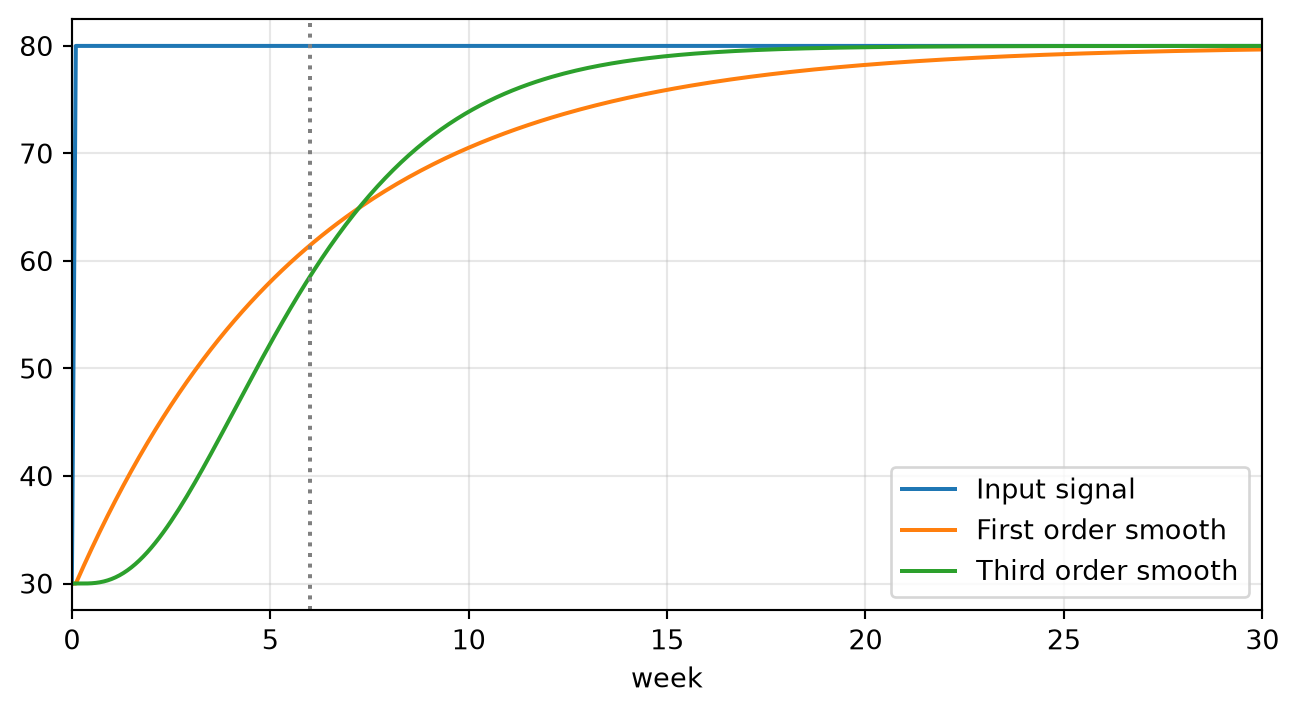

In [2]:
sm = lb.molecule("smooth")
fig, ax = plt.subplots(figsize=(8, 4))
d = sm.run(preset="Step up")      # input 80, smoothing time 6 weeks
d[["Input signal", "First order smooth", "Third order smooth"]].plot(ax=ax)
ax.axvline(6, c="grey", ls=":"); ax.set_xlim(0, 30); ax.set_xlabel("week"); ax.grid(alpha=0.3)
for week in (1, 6, 12):
    print(f"week {week:>2}: first order {d['First order smooth'][week]:4.1f}, third order {d['Third order smooth'][week]:4.1f}")

After one smoothing time (week 6), both beliefs have closed a bit less than two thirds of the gap of 50: they sit near 61 and 59. The difference is in the start. The first-order belief reacts at once, while the third-order belief barely moves in the first week (30.4 against 37.0) and then catches up in an S-shape. Both have the same average delay; they spread it differently.

**Try it.** Use the presets *Snappy (τ=2)*, *Step up* (τ=6) and *Slow (τ=15)*. For each, in which week does the first-order belief come within 2.5 of the new value (95% of the gap)? Is there a rule of thumb?

<details><summary>Show a worked answer</summary>

Weeks 6.0, 18.0 and 44.9. That is about three smoothing times each time, the same rule as for any first-order goal-seeking loop. (Euler steps of 0.1 close slightly more of the gap each step than the exact curve does, which is why the slow case comes in just under 45.)
</details>

In [3]:
for preset in ("Snappy (τ=2)", "Step up", "Slow (τ=15)"):
    f = sm.run(preset=preset)["First order smooth"]
    print(f"{preset:<13}: within 2.5 of 80 in week {f.index[f >= 77.5][0]:.1f}")

Snappy (τ=2) : within 2.5 of 80 in week 6.0
Step up      : within 2.5 of 80 in week 18.0
Slow (τ=15)  : within 2.5 of 80 in week 44.9


## 2. A smoothed belief always trails growth

When the thing you watch keeps growing, a smoothed belief never catches up. In **Trend & Extrapolation** (`trend`), an actual quantity grows 6% a month and the `Perceived` value smooths it over a `Perception time` of 4 months.

Perceived / actual at month 10: 0.815, month 60: 0.806
The perception is 3.6 months of growth behind


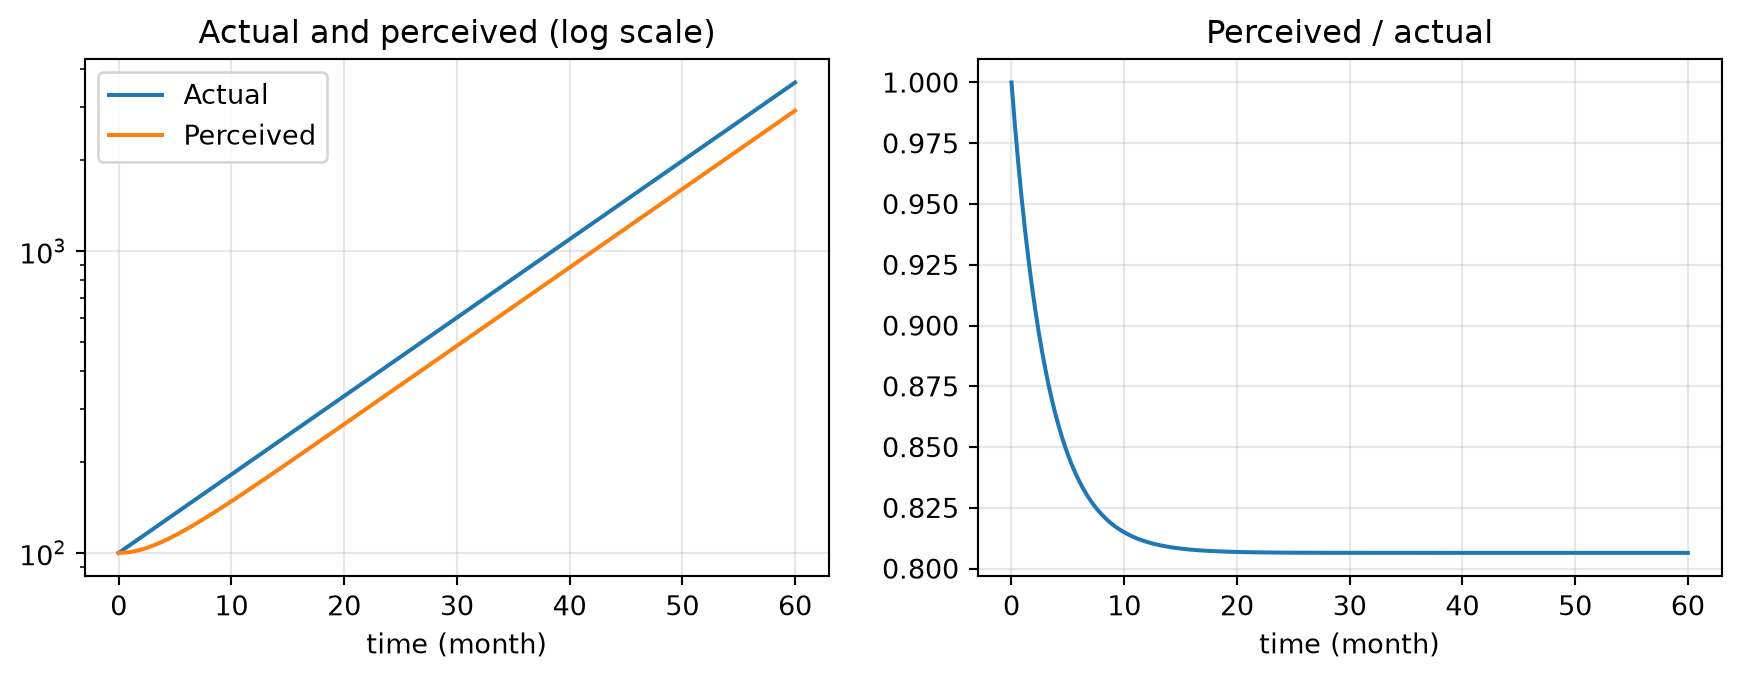

In [4]:
import numpy as np

tr = lb.molecule("trend")
d = tr.run()
ratio = d["Perceived"] / d["Actual"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
d[["Actual", "Perceived"]].plot(ax=ax1, logy=True, title="Actual and perceived (log scale)")
ratio.plot(ax=ax2, title="Perceived / actual")
for ax in (ax1, ax2): ax.grid(alpha=0.3)
print(f"Perceived / actual at month 10: {ratio[10]:.3f}, month 60: {ratio.iloc[-1]:.3f}")
print(f"The perception is {np.log(1 / ratio.iloc[-1]) / 0.06:.1f} months of growth behind")

The gap does not close: the perceived value settles at a fixed 81% of the actual one, about 3.6 months of growth behind. With steady growth `g` and perception time `τ`, the ratio is close to `1 / (1 + g τ) = 1 / 1.24 = 0.806`. Anyone who plans from the perceived value, for example sizing capacity, will always build too little while growth lasts.

**Try it.** Change `perception_time` to 1 and to 8 months. How far behind is the belief now? Then try the *Turning point* preset, where the quantity shrinks 4% a month: which way is the error now?

<details><summary>Show a worked answer</summary>

With a perception time of 1 month the belief is 94% of the actual value, about 1 month behind; with 8 months it is only 68%, about 6.5 months behind. When the quantity shrinks, the error flips: the belief ends 19% *above* the actual value (a ratio of 1.19), so a shrinking market looks bigger than it is.
</details>

In [5]:
for tp in (1, 4, 8):
    r = tr.run(perception_time=tp)
    ratio = r["Perceived"].iloc[-1] / r["Actual"].iloc[-1]
    print(f"perception time {tp}: perceived / actual {ratio:.3f}, about {np.log(1 / ratio) / 0.06:.1f} months behind")
r = tr.run(preset="Turning point")
print(f"Turning point: perceived / actual {r['Perceived'].iloc[-1] / r['Actual'].iloc[-1]:.2f}")

perception time 1: perceived / actual 0.943, about 1.0 months behind
perception time 4: perceived / actual 0.806, about 3.6 months behind
perception time 8: perceived / actual 0.676, about 6.5 months behind
Turning point: perceived / actual 1.19


## 3. Extrapolation works until the trend turns

A smarter forecaster corrects for the lag by estimating the trend and projecting it forward. **Extrapolation (forecast from the fractional trend)** (`extrapolation`) does that: it compares the perceived value with an older, smoothed value, turns the difference into a growth rate, and projects the perceived value forward over the perception delay plus a `Forecast horizon` of 5 years. The quantity grows a steady 3% a year. The cell runs it, then breaks the trend in a copy of the spec: growth becomes `3 - STEP(6, 30)`, so 3% a year until year 30 and a 3% a year decline after it.

steady growth, year 20: forecast for year 25 is 207.1, actual then 211.5
steady growth, year 40: forecast for year 45 is 377.2, actual then 385.0


with a turn: forecast made in year 30 for year 35 is 279.5, actual then 211.4


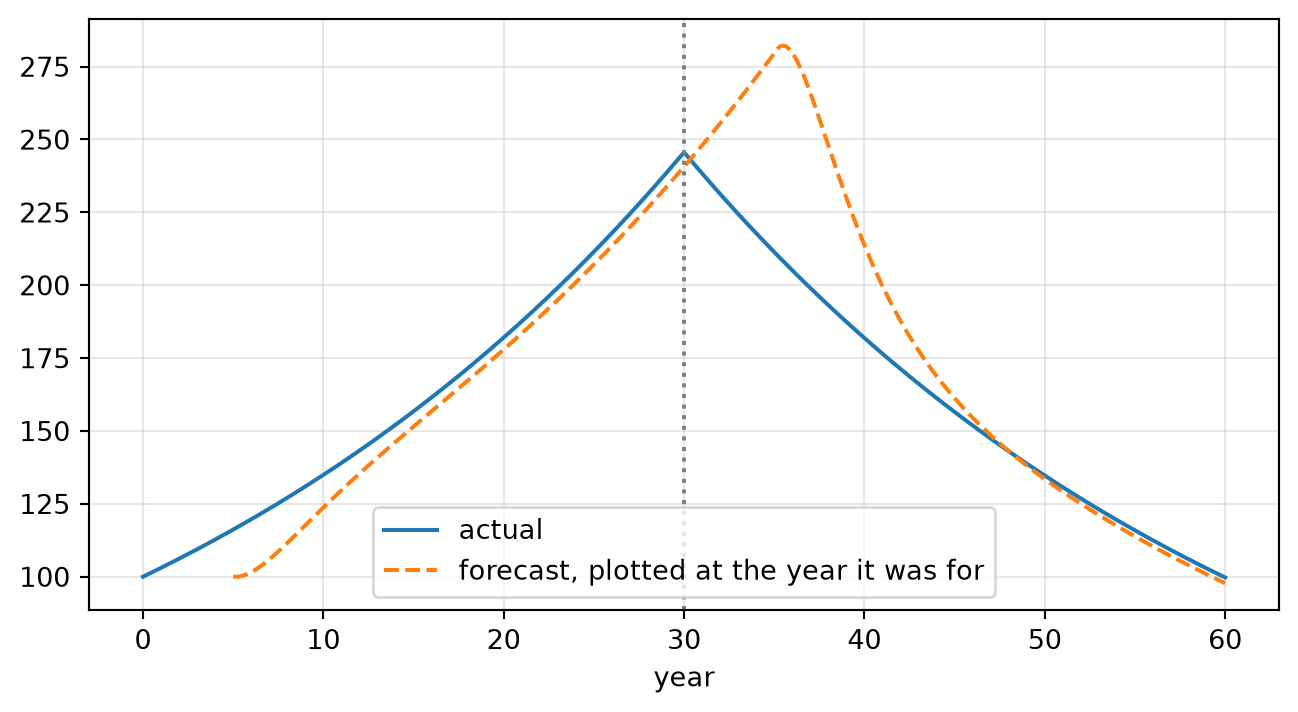

In [6]:
ex = lb.molecule("extrapolation")
d = ex.run()
for year in (20, 40):
    print(f"steady growth, year {year}: forecast for year {year + 5} is {d['Extrapolated quantity'][year]:5.1f}, "
          f"actual then {d['Actual quantity'][year + 5]:5.1f}")

import copy
spec = copy.deepcopy(ex.spec)
for v in spec["model"]["vars"]:
    if v["name"] == "Growth of actual quantity":
        v["eq"] = "3 - STEP(6, 30)"       # 3% a year, then from year 30 a 3% decline
turn = lb.Model.from_spec(spec).run()

fig, ax = plt.subplots(figsize=(8, 4))
turn["Actual quantity"].plot(ax=ax, label="actual")
turn["Extrapolated quantity"].shift(50).plot(ax=ax, ls="--", label="forecast, plotted at the year it was for")
ax.axvline(30, c="grey", ls=":"); ax.set_xlabel("year"); ax.legend(); ax.grid(alpha=0.3)
print(f"with a turn: forecast made in year 30 for year 35 is {turn['Extrapolated quantity'][30]:.1f}, actual then {turn['Actual quantity'][35]:.1f}")

In steady growth the forecast is good: about 2% below what actually happens five years later. (`shift(50)` moves each forecast 50 rows, which is 5 years at `dt = 0.1`, so it lines up with the year it predicts.) With the turn, the quantity peaks at about 246 in year 30, but the forecast made then says 280 for year 35, when the real value is 211. The forecaster keeps projecting growth for a while after the turn, because the trend estimate is built from smoothed, delayed data. A rule that forecasts well in steady times gives no warning of a turning point.

**Try it.** After the turn, how long does it take until the forecast's trend (`Fractional trend`) is negative, and when does it settle near the new −3%?

<details><summary>Show a worked answer</summary>

The next cell finds it: the estimated trend first goes negative at about year 34, four years after the turn, and comes within 0.1 points of −3% (below −2.9%) only around year 46. For four years the forecaster still believes in growth.
</details>

In [7]:
trend = turn["Fractional trend"]
after = trend[trend.index > 30]
print(f"Trend first negative in year {after.index[after < 0][0]:.1f}")
print(f"Trend below -2.9% from year {after.index[after < -0.029][0]:.1f}")

Trend first negative in year 34.1
Trend below -2.9% from year 45.9


## 4. Anchoring and adjustment: moving too little

People often judge a number by starting from an anchor and adjusting for the evidence, and the adjustment tends to be too small. **Univariate Anchoring and Adjustment** (`univariateAnchor`) writes this as `Value = Anchor × (Current / Normal) ^ Adjustment strength`. A strength of 1 is a full, proportional adjustment; 0.5 adjusts by the square root.

In [8]:
ua = lb.molecule("univariateAnchor")
print("cue   | strength 0.5 | strength 1")
for cue in (100, 150, 200, 400):
    half = ua.run(current_value_of_variable=cue)["Value"].iloc[-1]
    full = ua.run(current_value_of_variable=cue, adjustment_strength=1)["Value"].iloc[-1]
    print(f"{cue:>5} | {half:>12.1f} | {full:>10.1f}")

cue   | strength 0.5 | strength 1
  100 |        100.0 |      100.0
  150 |        122.5 |      150.0
  200 |        141.4 |      200.0
  400 |        200.0 |      400.0


With a strength of 0.5, a cue 50% above normal moves the judgement only 22.5%, and a cue four times normal only doubles it. The anchor holds the judgement back, and the bigger the change in the world, the bigger the error.

**Try it.** With strength 0.5, how large must the cue be before the judgement reaches 150, the value a full adjustment gives for a cue of 150?

<details><summary>Show a worked answer</summary>

The judgement is `100 × (cue / 100) ^ 0.5`, so reaching 150 needs `(cue / 100) ^ 0.5 = 1.5`, a cue of `100 × 1.5² = 225`. The run gives exactly 150 for a cue of 225: the evidence has to be more than twice as strong to move an anchored judgement as far.
</details>

In [9]:
print(f"Cue 225, strength 0.5: value {ua.run(current_value_of_variable=225)['Value'].iloc[-1]:.1f}")

Cue 225, strength 0.5: value 150.0


## Where next

- Back in the app: [Bounded rationality and expectations](https://waelrash1.github.io/loopbricks/#/learn/behaviour) explains why sensible people make these errors and how to model them, with a price war as an example.
- Smoothing and delays are covered in more depth in [Delays](https://waelrash1.github.io/loopbricks/#/learn/delays); goals that anchor on past results are the eroding goals archetype in [System archetypes](https://waelrash1.github.io/loopbricks/#/learn/archetypes).
- Expectations that trail reality drive the swings in [Cycles in business, labour and commodity markets](https://waelrash1.github.io/loopbricks/#/learn/cycles). For the behavioural background, see Sterman (2000, ch. 15 and 16).